# 04 – Refined data visualization

Builds on the composites from notebook 02. Static figures for the weekly slides (saved to `figures/`) and one interactive before/after map.

1. Colour composites per AOI
2. Seasonal NDVI trajectories (forest pixels)
3. Change maps vs. the 2017 baseline
4. Comparing the AOIs (distributions)
5. Terrain context (elevation vs. change)
6. Interactive side-by-side map

In [1]:
import sys, warnings
from pathlib import Path
sys.path.append(str(Path("..").resolve() / "scripts"))   # folder containing sds_utils.py

import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import sds_utils as su
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

YEARS = [2017, 2018, 2019, 2020, 2022, 2024, 2025, 2026]
BASE_YEAR, BASE_WIN = 2017, "late"
AOI_SHOW = "ajoie_ju"                      # AOI for the detailed panels
COL = {"ajoie_ju": "#c0392b", "fricktal_ag": "#2874a6", "valais_rhone": "#b9770e"}

def stack(aoi, var, window):
    arrs, yrs = [], []
    for y in YEARS:
        p = su.composite_path(aoi, y, window)
        if p.exists():
            arrs.append(su.open_nc(p)[var].load().drop_vars("spatial_ref", errors="ignore")); yrs.append(y)
    return xr.concat(arrs, dim=pd.Index(yrs, name="year"))

anc = {a: su.open_nc(su.PROC / f"{a}_ancillary.nc").load() for a in su.AOIS}
forest = {a: anc[a]["forest"].values == 1 for a in su.AOIS}
print({a: int(m.sum()) for a, m in forest.items()}, "forest pixels")

{'ajoie_ju': 669154, 'fricktal_ag': 671475, 'valais_rhone': 843613} forest pixels


## 1 · Colour composites (late window): true colour vs. SWIR false colour
SWIR-NIR-Red (B11-B08-B04) makes canopy moisture loss and bare/dead canopy stand out more than true colour.

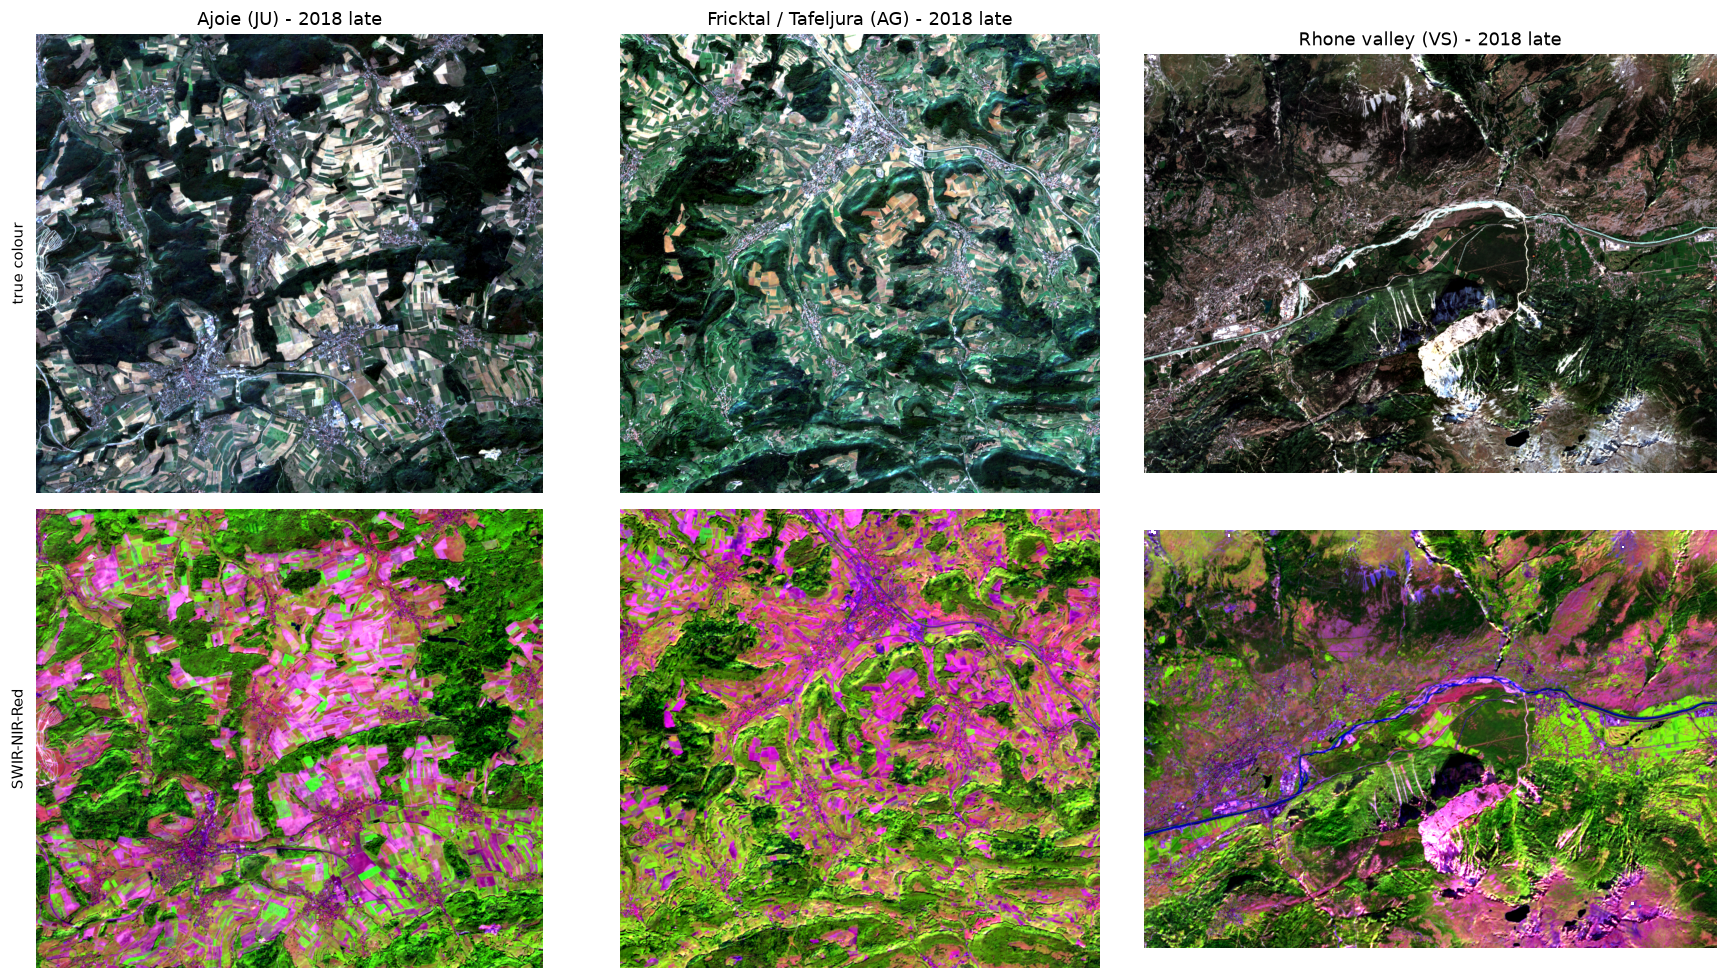

In [2]:
def colour_panel(year, window="late"):
    fig, ax = plt.subplots(2, 3, figsize=(16, 9))
    for j, aoi in enumerate(su.AOIS):
        ds = su.open_nc(su.composite_path(aoi, year, window)).load()
        ax[0, j].imshow(su.rgb(ds)); ax[0, j].set_title(f"{su.AOIS[aoi]['label']} - {year} {window}")
        ax[1, j].imshow(su.rgb(ds, ("B11", "B08", "B04"), 2, 98))
        ax[0, j].axis("off"); ax[1, j].axis("off")
    ax[0, 0].text(-0.02, 0.5, "true colour", transform=ax[0, 0].transAxes, rotation=90, va="center", ha="right")
    ax[1, 0].text(-0.02, 0.5, "SWIR-NIR-Red", transform=ax[1, 0].transAxes, rotation=90, va="center", ha="right")
    plt.tight_layout(); plt.savefig(su.FIGS / f"04_colour_{year}_{window}.png", dpi=150); plt.show()

colour_panel(2018)

## 2 · Seasonal NDVI trajectories
Median and inter-quartile range of NDVI over forest pixels. Windows are plotted separately because the late window carries the senescence signal.

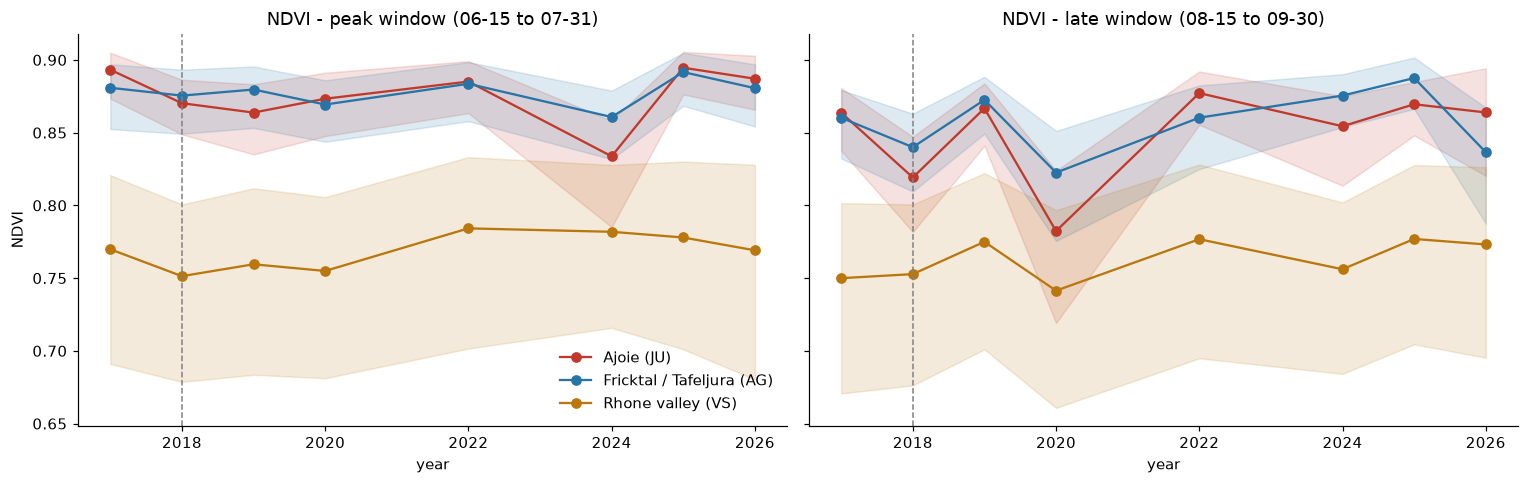

In [3]:
def trajectory(var="NDVI"):
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
    for k, w in enumerate(su.WINDOWS):
        for aoi in su.AOIS:
            s = stack(aoi, var, w)
            m = forest[aoi]
            vals = np.array([s.sel(year=y).values[m] for y in s.year.values], dtype=object)
            med = [np.nanmedian(v) for v in vals]; q1 = [np.nanpercentile(v, 25) for v in vals]; q3 = [np.nanpercentile(v, 75) for v in vals]
            ax[k].plot(s.year, med, "-o", color=COL[aoi], label=su.AOIS[aoi]["label"])
            ax[k].fill_between(s.year, q1, q3, color=COL[aoi], alpha=0.15)
        ax[k].axvline(2018, color="grey", ls="--", lw=1); ax[k].set_title(f"{var} - {w} window ({su.WINDOWS[w][0]} to {su.WINDOWS[w][1]})")
        ax[k].set_xlabel("year")
    ax[0].set_ylabel(var); ax[0].legend(frameon=False)
    plt.tight_layout(); plt.savefig(su.FIGS / f"04_trajectory_{var}.png", dpi=150); plt.show()

trajectory("NDVI")

## 3 · Change vs. the 2017 baseline
Δ = index(year) − index(2017), same window. Diverging colour map centred on 0 (blue = increase, red = decrease). Only forest pixels are shown.

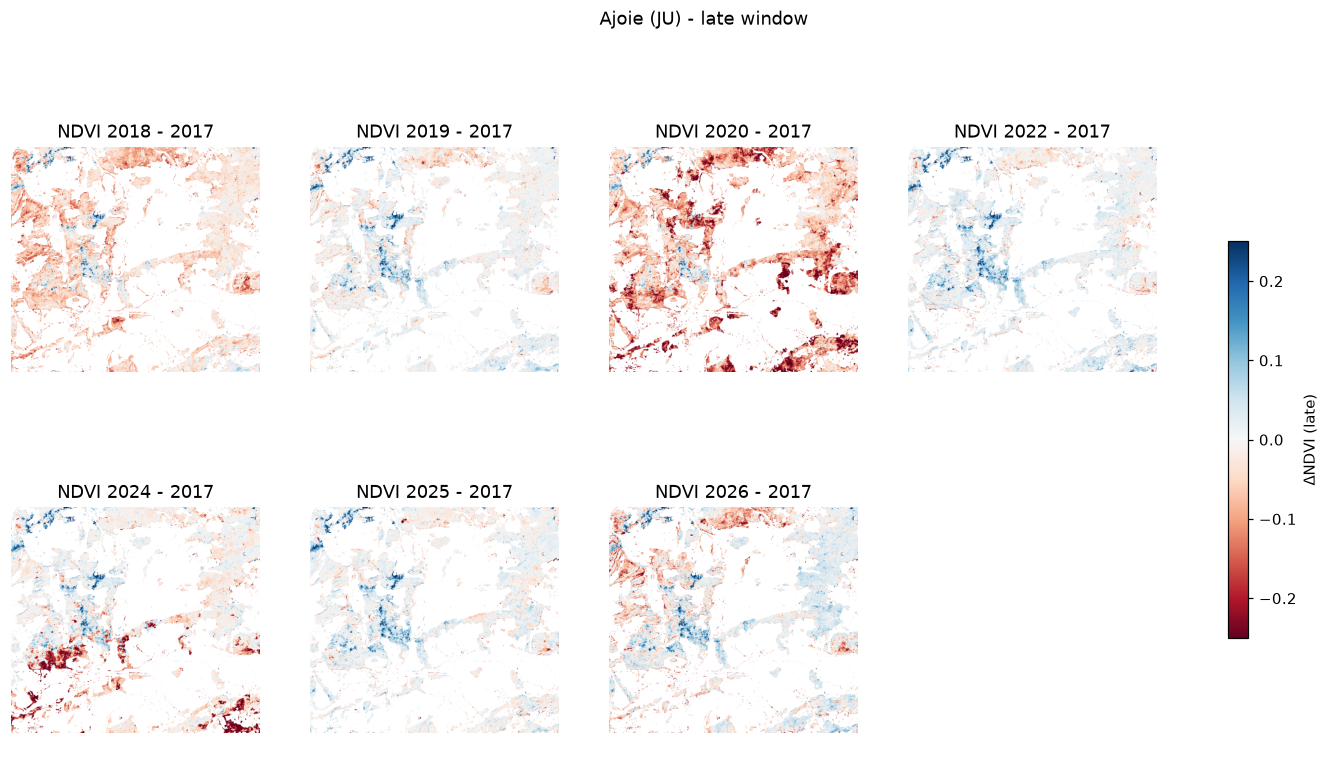

In [4]:
def delta_maps(aoi, var="NDVI", window=BASE_WIN, vlim=0.25):
    s = stack(aoi, var, window)
    base = s.sel(year=BASE_YEAR)
    yrs = [y for y in s.year.values if y != BASE_YEAR]
    ncol = 4; nrow = int(np.ceil(len(yrs) / ncol))
    fig, ax = plt.subplots(nrow, ncol, figsize=(4.2 * ncol, 3.9 * nrow), squeeze=False)
    norm = TwoSlopeNorm(vcenter=0, vmin=-vlim, vmax=vlim)
    for a in ax.ravel(): a.axis("off")
    for a, y in zip(ax.ravel(), yrs):
        d = (s.sel(year=y) - base).where(forest[aoi])
        im = a.imshow(d, cmap="RdBu", norm=norm); a.set_title(f"{var} {y} - {BASE_YEAR}")
    fig.colorbar(im, ax=ax, shrink=0.6, label=f"Δ{var} ({window})")
    fig.suptitle(f"{su.AOIS[aoi]['label']} - {window} window", y=0.995)
    plt.savefig(su.FIGS / f"04_delta_{var}_{aoi}_{window}.png", dpi=150, bbox_inches="tight"); plt.show()

delta_maps(AOI_SHOW)

## 4 · Comparing the AOIs
ECDF of ΔNDVI (2018 vs 2017, late window) for forest pixels. A larger left tail means more canopy loss. This is a proxy for stress, not a dieback label.

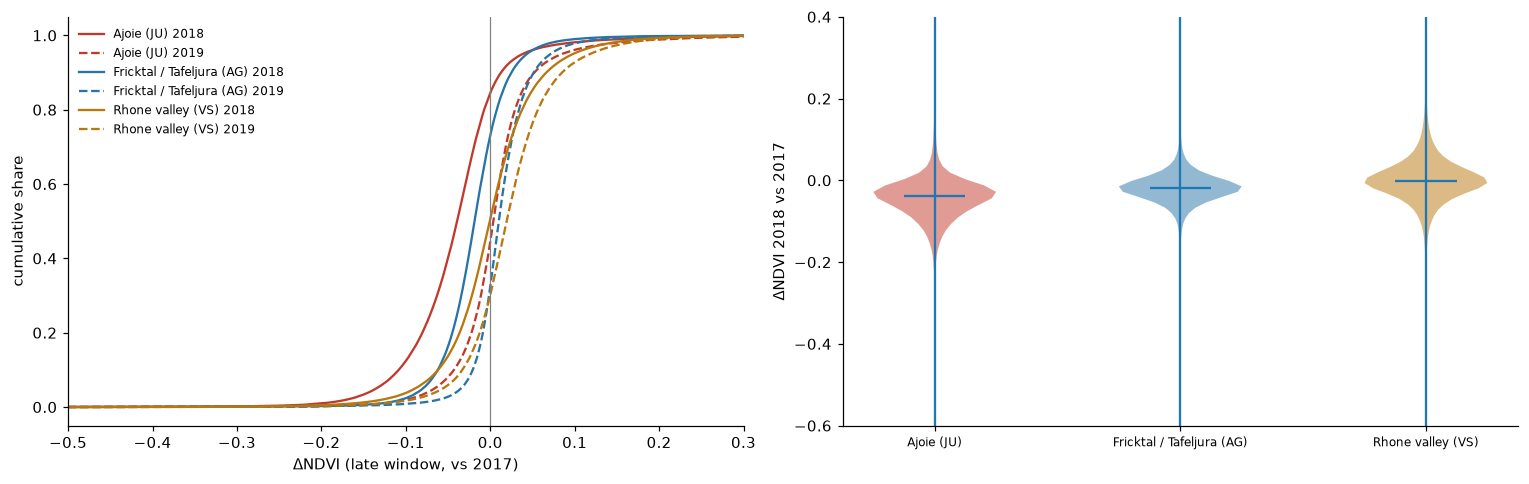

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for aoi in su.AOIS:
    for y, ls in ((2018, "-"), (2019, "--")):
        s = stack(aoi, "NDVI", "late")
        if y not in s.year.values: continue
        d = (s.sel(year=y) - s.sel(year=BASE_YEAR)).values[forest[aoi]]
        d = np.sort(d[np.isfinite(d)])
        ax[0].plot(d, np.linspace(0, 1, len(d)), ls, color=COL[aoi], label=f"{su.AOIS[aoi]['label']} {y}")
ax[0].axvline(0, color="grey", lw=0.8); ax[0].set_xlim(-0.5, 0.3)
ax[0].set_xlabel("ΔNDVI (late window, vs 2017)"); ax[0].set_ylabel("cumulative share"); ax[0].legend(frameon=False, fontsize=8)

data = []
for aoi in su.AOIS:
    s = stack(aoi, "NDVI", "late")
    d = (s.sel(year=2018) - s.sel(year=BASE_YEAR)).values[forest[aoi]]
    data.append(d[np.isfinite(d)])
vp = ax[1].violinplot(data, showmedians=True)
for b, a in zip(vp["bodies"], su.AOIS): b.set_facecolor(COL[a]); b.set_alpha(0.5)
ax[1].set_xticks(range(1, 4)); ax[1].set_xticklabels([su.AOIS[a]["label"] for a in su.AOIS], fontsize=8)
ax[1].set_ylabel("ΔNDVI 2018 vs 2017"); ax[1].set_ylim(-0.6, 0.4)
plt.tight_layout(); plt.savefig(su.FIGS / "04_aoi_comparison.png", dpi=150); plt.show()

## 5 · Terrain context
Median ΔNDVI (2018 vs 2017, late) by elevation band; shaded = inter-quartile range. Helps to judge whether the AOIs are comparable along the elevation gradient.

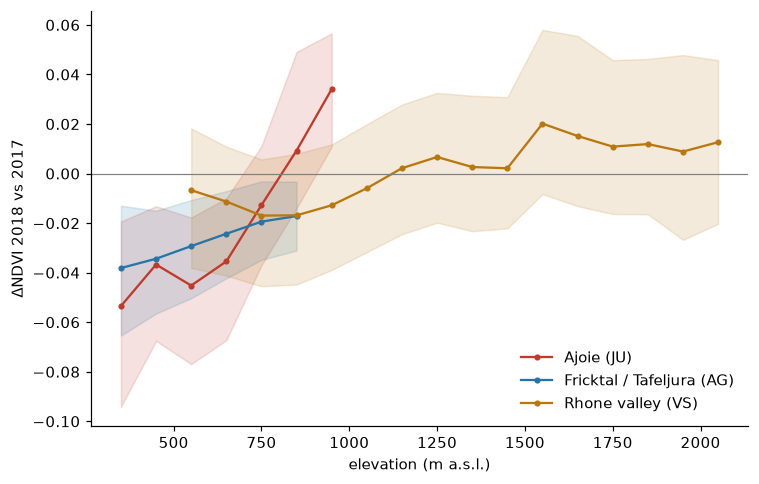

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for aoi in su.AOIS:
    s = stack(aoi, "NDVI", "late")
    d = (s.sel(year=2018) - s.sel(year=BASE_YEAR)).values
    e = anc[aoi]["elevation"].values
    m = forest[aoi] & np.isfinite(d)
    bins = np.arange(200, 2200, 100)
    df = pd.DataFrame({"e": e[m], "d": d[m]}); df["bin"] = pd.cut(df.e, bins)
    g = df.groupby("bin", observed=True)["d"].agg(["median", lambda x: x.quantile(.25), lambda x: x.quantile(.75), "size"])
    g.columns = ["med", "q1", "q3", "n"]; g = g[g.n > 200]
    x = [i.mid for i in g.index]
    ax.plot(x, g.med, "-o", ms=3, color=COL[aoi], label=su.AOIS[aoi]["label"]); ax.fill_between(x, g.q1, g.q3, color=COL[aoi], alpha=0.15)
ax.axhline(0, color="grey", lw=0.8); ax.set_xlabel("elevation (m a.s.l.)"); ax.set_ylabel("ΔNDVI 2018 vs 2017"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(su.FIGS / "04_delta_by_elevation.png", dpi=150); plt.show()

## 6 · Interactive side-by-side map
Left: NDVI late 2017 (baseline). Right: ΔNDVI late 2018 vs 2017 (forest only). Both panels are synchronised (`folium.plugins.DualMap`), raster layers are exported as transparent PNG overlays.


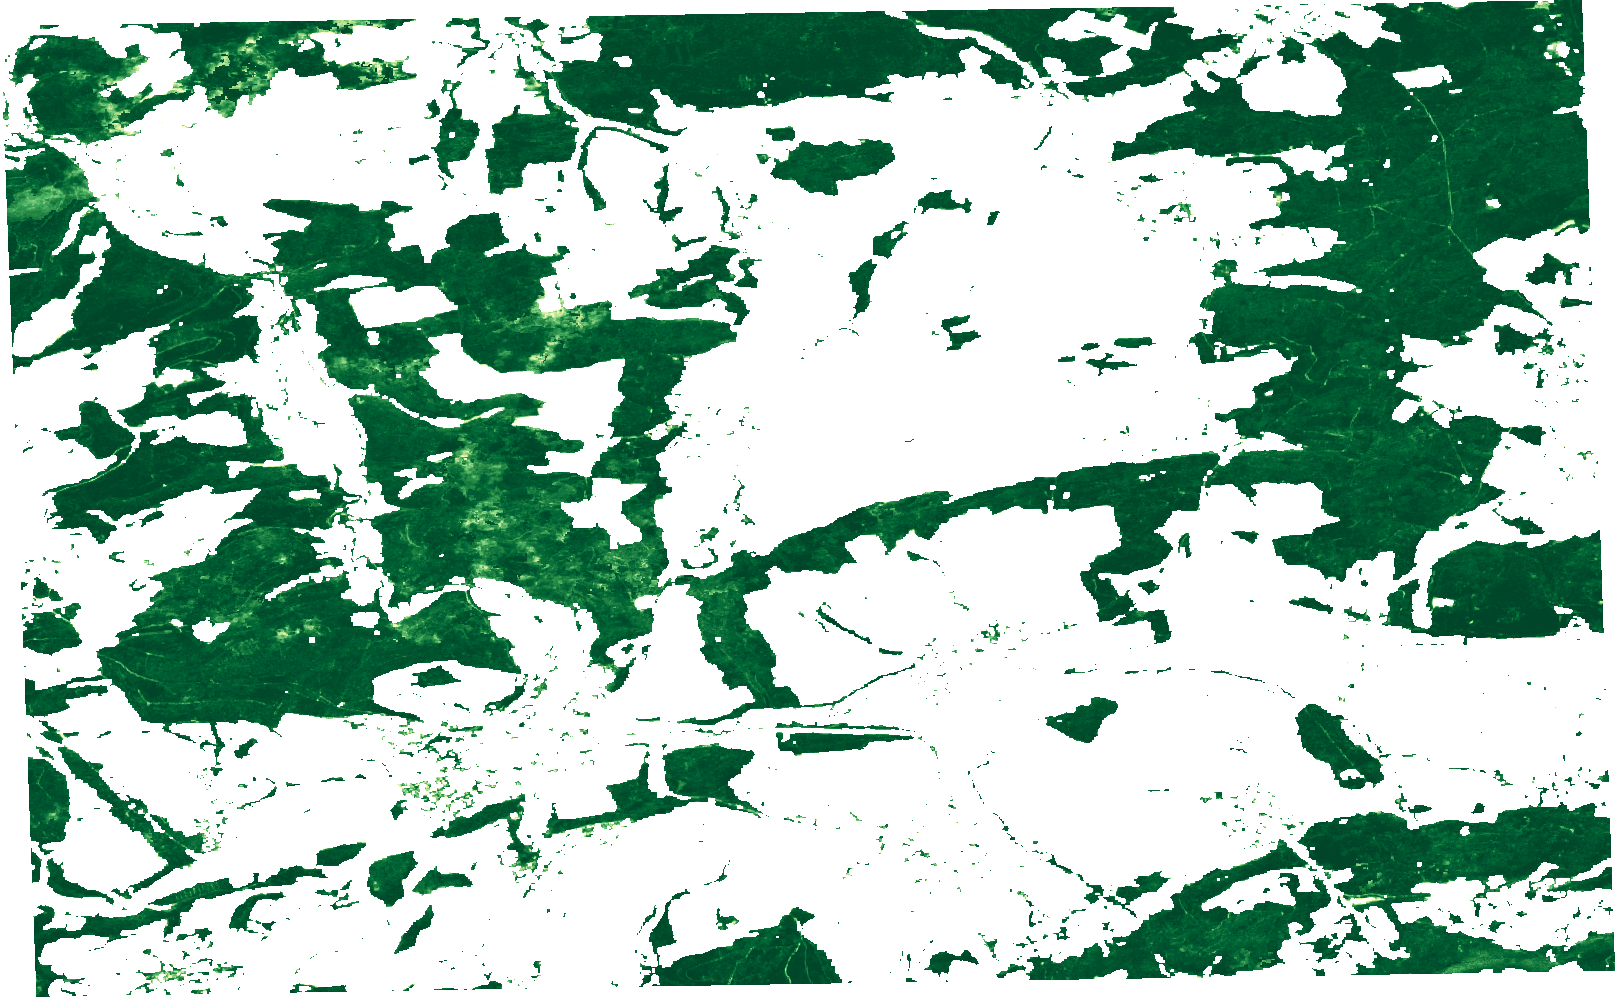
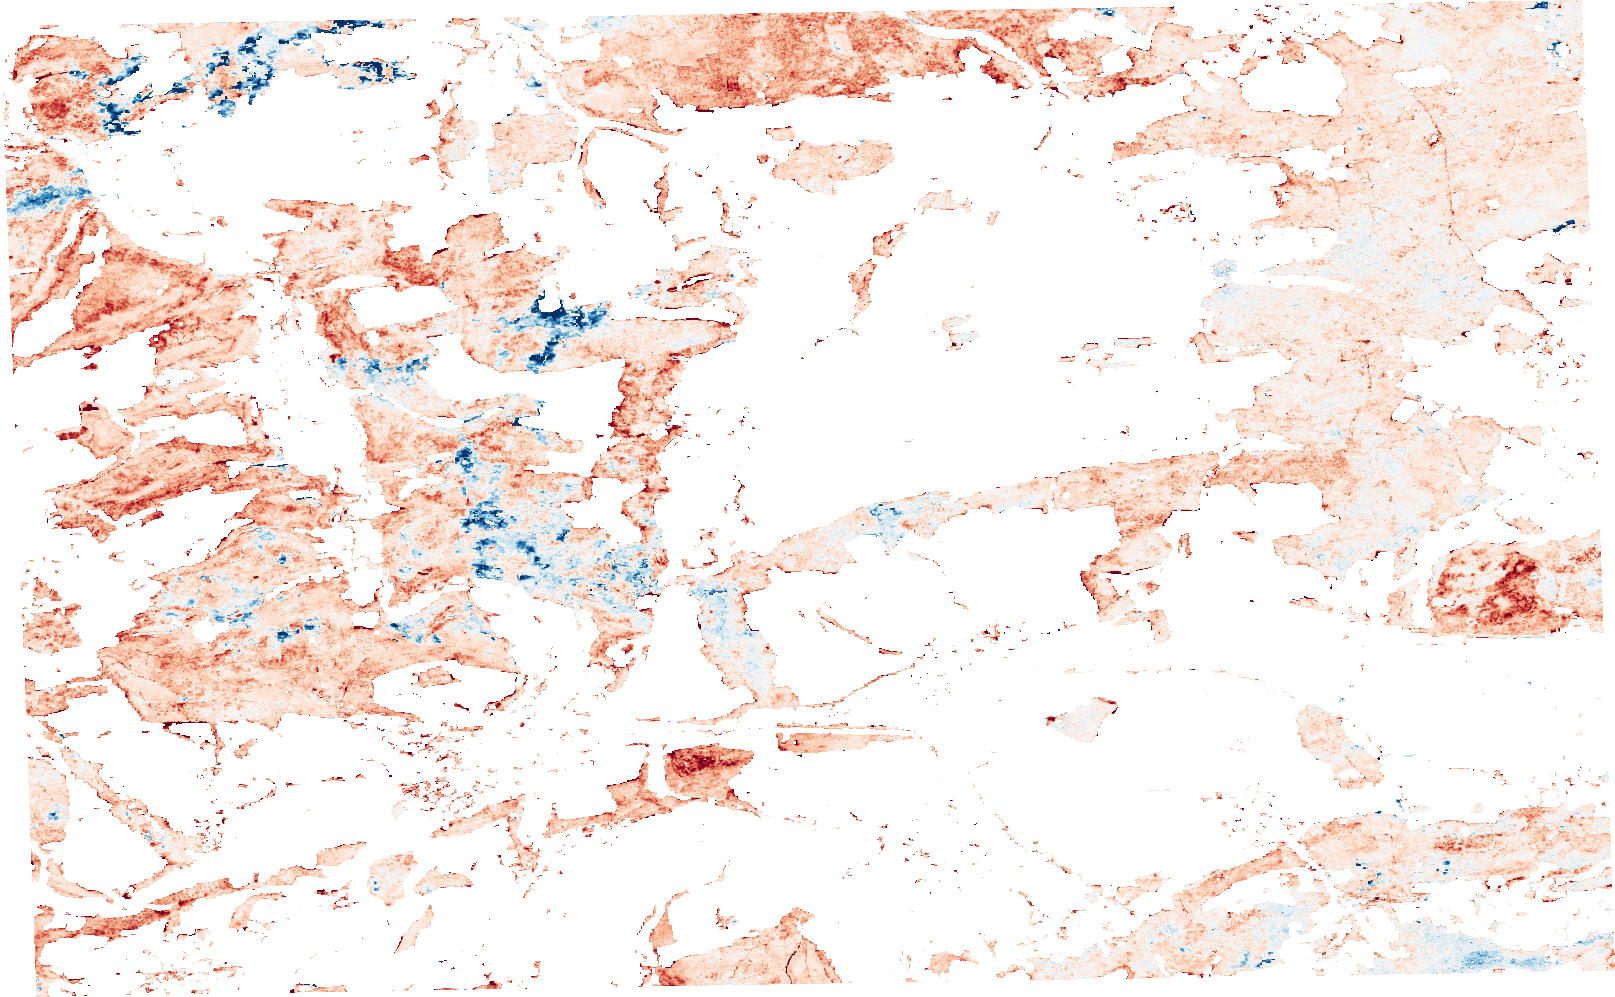

In [7]:
import folium
from folium.plugins import DualMap

aoi = AOI_SHOW
s = stack(aoi, "NDVI", "late")
left = s.sel(year=2017).where(forest[aoi])
right = (s.sel(year=2018) - s.sel(year=2017)).where(forest[aoi])
img_l, bnds = su.overlay_png(left, "YlGn", 0.3, 0.9)
img_r, _ = su.overlay_png(right, "RdBu", -0.25, 0.25)

x0, y0, x1, y1 = su.AOIS[aoi]["bbox"]
m = DualMap(location=[(y0 + y1) / 2, (x0 + x1) / 2], zoom_start=12, tiles=None)
folium.TileLayer(tiles="https://wmts.geo.admin.ch/1.0.0/ch.swisstopo.pixelkarte-farbe/default/current/3857/{z}/{x}/{y}.jpeg", attr="© swisstopo", name="swisstopo map").add_to(m.m1)
folium.TileLayer(tiles="https://wmts.geo.admin.ch/1.0.0/ch.swisstopo.swissimage/default/current/3857/{z}/{x}/{y}.jpeg", attr="© swisstopo", name="SWISSIMAGE").add_to(m.m2)
folium.raster_layers.ImageOverlay(img_l, bnds, opacity=0.85, name="NDVI late 2017").add_to(m.m1)
folium.raster_layers.ImageOverlay(img_r, bnds, opacity=0.85, name="ΔNDVI 2018-2017").add_to(m.m2)
folium.LayerControl(collapsed=False).add_to(m)
m.save(su.FIGS / f"04_dualmap_{aoi}.html")
m

## Notes
- Figures are written to `figures/` for the weekly slides (what worked / what did not: note e.g. windows with few valid observations).
- ΔNDVI between years is sensitive to phenology and residual cloud/haze; compare only identical windows and check `n_obs`.
- Next: notebook 05 detects canopy units and aggregates these layers per unit.